Authors: Myles Lewis & Joonseo Bang

Background information:
This dataset contains records of simulation crashes encountered during climate model uncertainty quantification (UQ) ensembles.



Dataset: https://archive.ics.uci.edu/dataset/252/climate+model+simulation+crashes



In [ ]:
!pip install pandas numpy scikit-learn matplotlib seaborn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [ ]:
import pandas as pd

pop_dataset = pd.read_csv(
    "pop_failures.dat",
    sep=r"\s+",
    header=0,          # <-- use the first row as column names
    engine="python"
)

print("Dataset shape:", pop_dataset.shape)
pop_dataset.head()

Dataset shape: (540, 21)


,Study,Run,vconst_corr,vconst_2,vconst_3,vconst_4,vconst_5,vconst_7,ah_corr,ah_bolus,...,efficiency_factor,tidal_mix_max,vertical_decay_scale,convect_corr,bckgrnd_vdc1,bckgrnd_vdc_ban,bckgrnd_vdc_eq,bckgrnd_vdc_psim,Prandtl,outcome
0,1,1,0.859036,0.927825,0.252866,0.298838,0.170521,0.735936,0.428325,0.567947,...,0.245675,0.104226,0.869091,0.997518,0.448620,0.307522,0.858310,0.796997,0.869893,0
1,1,2,0.606041,0.457728,0.359448,0.306957,0.843331,0.934851,0.444572,0.828015,...,0.616870,0.975786,0.914344,0.845247,0.864152,0.346713,0.356573,0.438447,0.512256,1
2,1,3,0.997600,0.373238,0.517399,0.504993,0.618903,0.605571,0.746225,0.195928,...,0.679355,0.803413,0.643995,0.718441,0.924775,0.315371,0.250642,0.285636,0.365858,1
3,1,4,0.783408,0.104055,0.197533,0.421837,0.742056,0.490828,0.005525,0.392123,...,0.471463,0.597879,0.761659,0.362751,0.912819,0.977971,0.845921,0.699431,0.475987,1
4,1,5,0.406250,0.513199,0.061812,0.635837,0.844798,0.441502,0.191926,0.487546,...,0.551543,0.743877,0.312349,0.650223,0.522261,0.043545,0.376660,0.280098,0.132283,1


In [ ]:
column_names = (
    ["study", "simulation"]
    + [f"param_{i}" for i in range(1, 19)]
    + ["outcome"]
)

pop_dataset.columns = column_names
pop_dataset.head()

,study,simulation,param_1,param_2,param_3,param_4,param_5,param_6,param_7,param_8,...,param_10,param_11,param_12,param_13,param_14,param_15,param_16,param_17,param_18,outcome
0,1,1,0.859036,0.927825,0.252866,0.298838,0.170521,0.735936,0.428325,0.567947,...,0.245675,0.104226,0.869091,0.997518,0.448620,0.307522,0.858310,0.796997,0.869893,0
1,1,2,0.606041,0.457728,0.359448,0.306957,0.843331,0.934851,0.444572,0.828015,...,0.616870,0.975786,0.914344,0.845247,0.864152,0.346713,0.356573,0.438447,0.512256,1
2,1,3,0.997600,0.373238,0.517399,0.504993,0.618903,0.605571,0.746225,0.195928,...,0.679355,0.803413,0.643995,0.718441,0.924775,0.315371,0.250642,0.285636,0.365858,1
3,1,4,0.783408,0.104055,0.197533,0.421837,0.742056,0.490828,0.005525,0.392123,...,0.471463,0.597879,0.761659,0.362751,0.912819,0.977971,0.845921,0.699431,0.475987,1
4,1,5,0.406250,0.513199,0.061812,0.635837,0.844798,0.441502,0.191926,0.487546,...,0.551543,0.743877,0.312349,0.650223,0.522261,0.043545,0.376660,0.280098,0.132283,1


In [ ]:
print(pop_dataset.info())

print("\nMissing values:")
print(pop_dataset.isnull().sum())

print("\nOutcome counts:")
print(pop_dataset["outcome"].value_counts())

print("\nBasic statistics:")
pop_dataset.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 540 entries, 0 to 539
Data columns (total 21 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   study       540 non-null    int64  
 1   simulation  540 non-null    int64  
 2   param_1     540 non-null    float64
 3   param_2     540 non-null    float64
 4   param_3     540 non-null    float64
 5   param_4     540 non-null    float64
 6   param_5     540 non-null    float64
 7   param_6     540 non-null    float64
 8   param_7     540 non-null    float64
 9   param_8     540 non-null    float64
 10  param_9     540 non-null    float64
 11  param_10    540 non-null    float64
 12  param_11    540 non-null    float64
 13  param_12    540 non-null    float64
 14  param_13    540 non-null    float64
 15  param_14    540 non-null    float64
 16  param_15    540 non-null    float64
 17  param_16    540 non-null    float64
 18  param_17    540 non-null    float64
 19  param_18    540 non-null    f

,study,simulation,param_1,param_2,param_3,param_4,param_5,param_6,param_7,param_8,...,param_10,param_11,param_12,param_13,param_14,param_15,param_16,param_17,param_18,outcome
count,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000,...,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000
mean,2.000000,90.500000,0.500026,0.500097,0.500027,0.500119,0.500001,0.499913,0.500059,0.500076,...,0.500111,0.499984,0.500032,0.499933,0.499944,0.499946,0.500044,0.500020,0.500021,0.914815
std,0.817254,52.008901,0.288939,0.288922,0.289067,0.288993,0.288827,0.288852,0.289010,0.288909,...,0.288966,0.289127,0.289014,0.288822,0.288949,0.288923,0.288813,0.288936,0.289013,0.279416
min,1.000000,1.000000,0.000414,0.001922,0.001181,0.001972,0.000858,0.000476,0.004590,0.000296,...,0.002015,0.000419,0.001188,0.001312,0.002509,0.000732,0.000891,0.000219,0.000263,0.000000
25%,1.000000,45.750000,0.249650,0.251597,0.251540,0.250158,0.250630,0.251325,0.253048,0.250402,...,0.250758,0.251676,0.249669,0.249988,0.249586,0.249974,0.250412,0.252739,0.249723,1.000000
50%,2.000000,90.500000,0.499998,0.499595,0.500104,0.500456,0.500903,0.499174,0.499070,0.500074,...,0.500393,0.500322,0.500151,0.500625,0.499080,0.499959,0.500384,0.498955,0.499431,1.000000
75%,3.000000,135.250000,0.750042,0.750011,0.749180,0.750348,0.748988,0.748166,0.750109,0.749091,...,0.749447,0.749346,0.749164,0.749569,0.750012,0.747978,0.749256,0.748539,0.749792,1.000000
max,3.000000,180.000000,0.999194,0.998815,0.998263,0.997673,0.998944,0.997142,0.998930,0.998506,...,0.999536,0.999942,0.997718,0.997518,0.999795,0.999155,0.997265,0.999306,0.999655,1.000000


In [ ]:
X = pop_dataset.drop(columns=["study", "simulation", "outcome"])
y = pop_dataset["outcome"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (540, 18)
Target shape: (540,)


In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled feature means:")
print(np.round(X_scaled.mean(axis=0), 3))

print("\nScaled feature standard deviations:")
print(np.round(X_scaled.std(axis=0), 3))

Scaled feature means:
[-0.  0.  0. -0. -0.  0. -0. -0. -0.  0. -0.  0. -0.  0.  0. -0.  0.  0.]

Scaled feature standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print("Explained variance by component:")
for i in range(len(explained_variance)):
    print(
        f"PC{i + 1}: {explained_variance[i]:.3f} "
        f"| cumulative: {cumulative_variance[i]:.3f}"
    )

Explained variance by component:
PC1: 0.060 | cumulative: 0.060
PC2: 0.060 | cumulative: 0.120
PC3: 0.059 | cumulative: 0.178
PC4: 0.058 | cumulative: 0.237
PC5: 0.058 | cumulative: 0.294
PC6: 0.057 | cumulative: 0.351
PC7: 0.057 | cumulative: 0.408
PC8: 0.056 | cumulative: 0.464
PC9: 0.056 | cumulative: 0.520
PC10: 0.056 | cumulative: 0.576
PC11: 0.055 | cumulative: 0.631
PC12: 0.054 | cumulative: 0.686
PC13: 0.054 | cumulative: 0.740
PC14: 0.053 | cumulative: 0.793
PC15: 0.053 | cumulative: 0.845
PC16: 0.052 | cumulative: 0.897
PC17: 0.051 | cumulative: 0.949
PC18: 0.051 | cumulative: 1.000


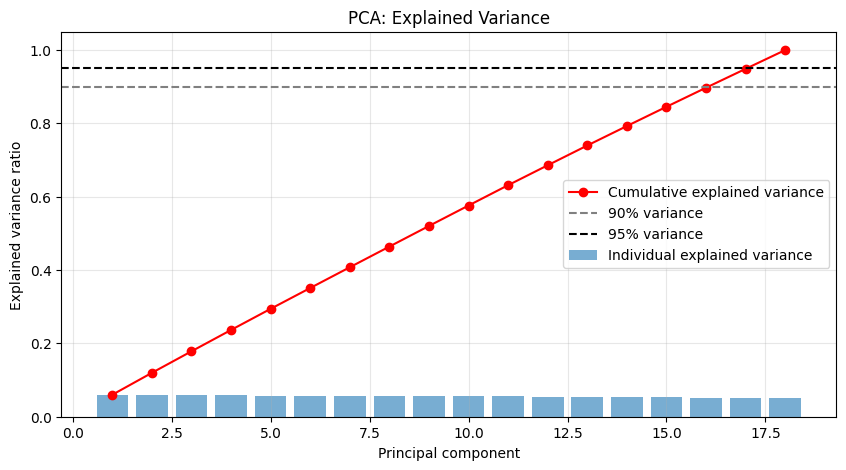

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    range(1, len(explained_variance) + 1),
    explained_variance,
    alpha=0.6,
    label="Individual explained variance"
)

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o",
    color="red",
    label="Cumulative explained variance"
)

plt.axhline(0.90, color="gray", linestyle="--", label="90% variance")
plt.axhline(0.95, color="black", linestyle="--", label="95% variance")

plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("PCA: Explained Variance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print(
    "Number of components needed to retain at least 95% variance:",
    n_components_95
)

Number of components needed to retain at least 95% variance: 18


In [ ]:
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca_2d,
    columns=["PC1", "PC2"]
)

pca_df["outcome"] = y.values

print("2-D PCA shape:", X_pca_2d.shape)
pca_df.head()

2-D PCA shape: (540, 2)


,PC1,PC2,outcome
0,1.041038,1.669467,0
1,-1.314527,-0.036798,1
2,-2.154176,0.781253,1
3,0.572453,-0.514516,1
4,-1.426957,-0.890555,1


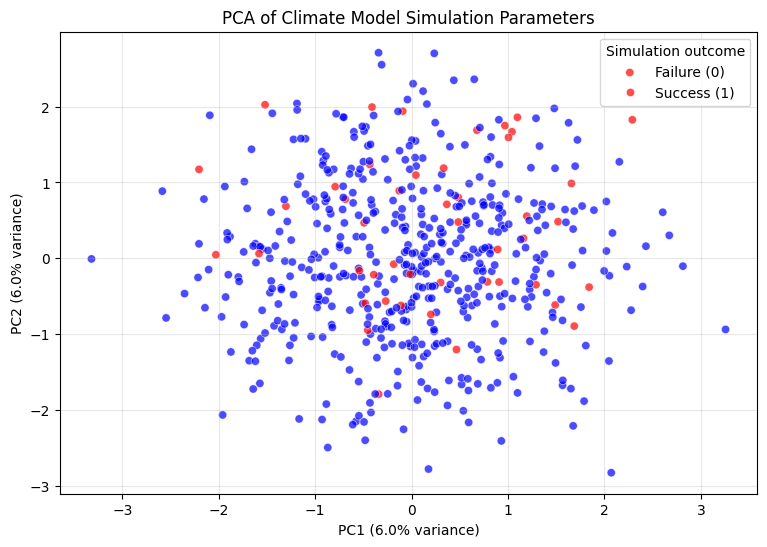

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="outcome",
    palette={0: "red", 1: "blue"},
    alpha=0.7
)

plt.title("PCA of Climate Model Simulation Parameters")
plt.xlabel(
    f"PC1 ({pca_2d.explained_variance_ratio_[0] * 100:.1f}% variance)"
)
plt.ylabel(
    f"PC2 ({pca_2d.explained_variance_ratio_[1] * 100:.1f}% variance)"
)
plt.legend(title="Simulation outcome", labels=["Failure (0)", "Success (1)"])
plt.grid(alpha=0.3)
plt.show()

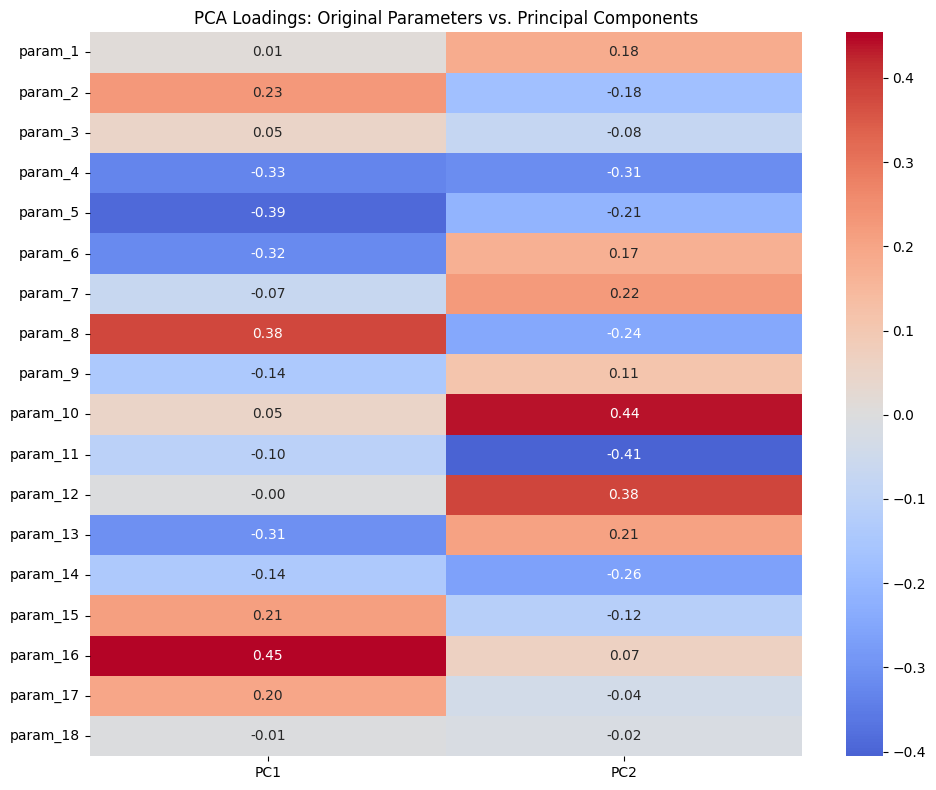

,PC1,PC2
param_1,0.012623,0.180152
param_2,0.227395,-0.176622
param_3,0.052484,-0.075098
param_4,-0.328863,-0.313029
param_5,-0.388698,-0.210812
param_6,-0.318385,0.172008
param_7,-0.066797,0.222832
param_8,0.377429,-0.244890
param_9,-0.141148,0.108239
param_10,0.051346,0.440093


In [ ]:
loadings = pd.DataFrame(
    pca_2d.components_.T,
    columns=["PC1", "PC2"],
    index=X.columns
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    loadings,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("PCA Loadings: Original Parameters vs. Principal Components")
plt.tight_layout()
plt.show()

loadings

In [ ]:
pca_df.to_csv("climate_model_pca_results.csv", index=False)
print("Saved: climate_model_pca_results.csv")

Saved: climate_model_pca_results.csv


In [ ]:
print(
    "PCA was applied to 18 standardized climate-model parameters from 540 simulations. "
    "The first two principal components summarize the largest sources of variation in the data. "
    "The scatter plot shows whether failed and successful simulations form separate groups. "
    "If the groups overlap, PCA shows that the variation in the input parameters does not clearly "
    "separate simulation outcomes. The loading heatmap identifies which original parameters "
    "contribute most to PC1 and PC2."
)

PCA was applied to 18 standardized climate-model parameters from 540 simulations. The first two principal components summarize the largest sources of variation in the data. The scatter plot shows whether failed and successful simulations form separate groups. If the groups overlap, PCA shows that the variation in the input parameters does not clearly separate simulation outcomes. The loading heatmap identifies which original parameters contribute most to PC1 and PC2.


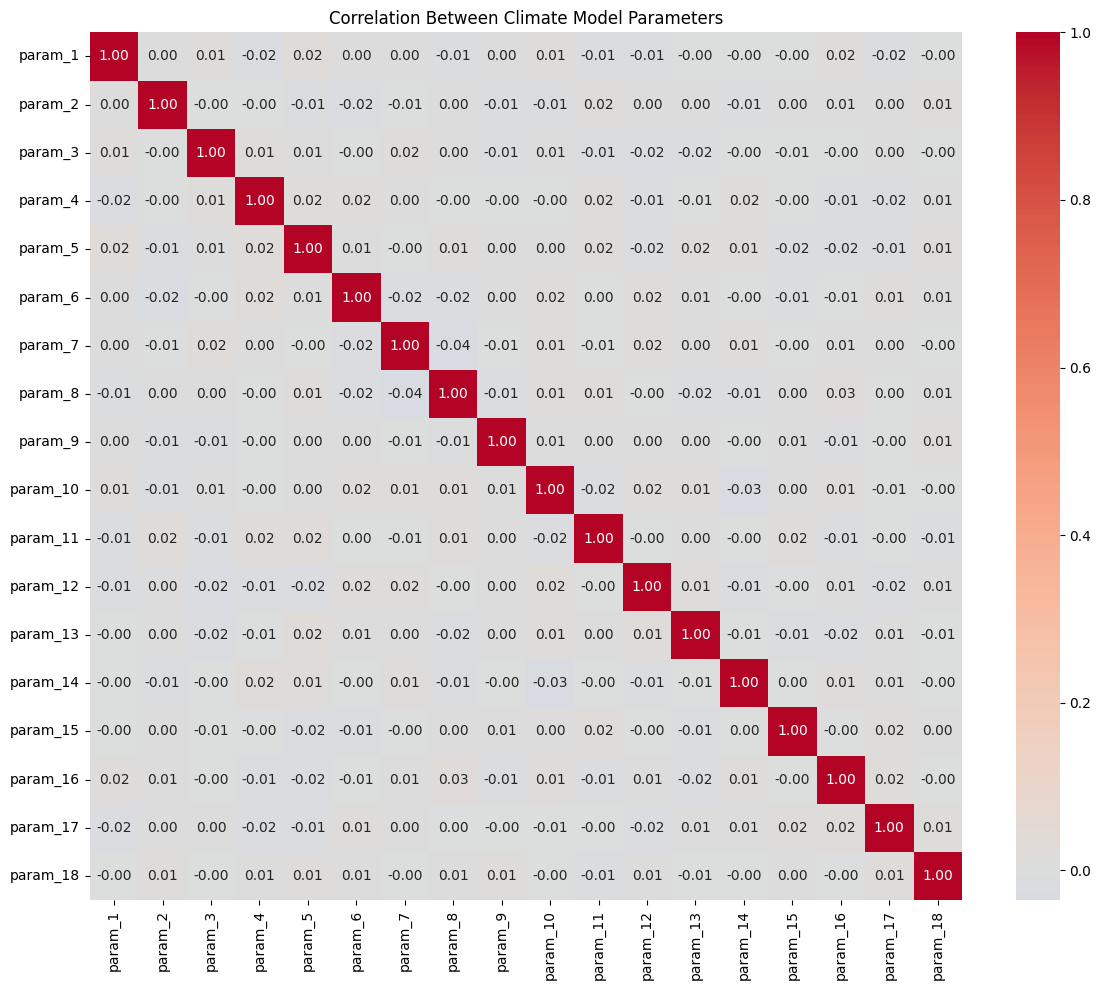

In [ ]:
plt.figure(figsize=(12, 10))
sns.heatmap(
    X.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Between Climate Model Parameters")
plt.tight_layout()
plt.show()